# TRUEGUARD v2 — Complete Experimental Verification (Google Colab GPU)

This notebook runs the **entire real implementation** of the TRUEGUARD architecture proposed in Section 6 of the review paper:
1. **Four real sensors** extracted from the LLM's own hidden states, attention matrices, and output logits (`src/tg_pipeline.py`):
   - **ISP** — per-layer linear probes **trained on labelled hidden states** (no std-dispersion proxy).
   - **AAS** — normalised Shannon entropy of final-quartile attention heads.
   - **EEM** — $0.6\,H_{\text{Shannon,norm}} + 0.4\,H_{\text{Rényi-2,norm}}$ of output logits.
   - **DST** — temporal cosine distance between consecutive layer-averaged hidden states.
2. **Leakage-free fusion training**: grouped 5-fold CV (both answers of a question stay in the same fold); inner out-of-fold probe scores feed the logistic-regression fusion layer.
3. **Two calibrated thresholds & three mitigation tiers** (`src/tg_controller.py`): Safe $\to$ Tier 1 risk-guided re-sampling $\to$ Tier 2 Wikipedia-grounded regeneration $\to$ Tier 3 calibrated abstention.
4. **Scientific evaluation**: in-distribution CV, single-sensor baselines, leave-one-sensor-out ablation + paired bootstrap significance test, sensor complementarity & correlations, cross-dataset generalisation matrix, real latency profiling, and before/after mitigation on TriviaQA.

**Before running:** `Runtime → Change runtime type → T4 GPU` (or L4 / A100).

## 1. GPU check & dependencies

In [2]:
!nvidia-smi
!pip -q install --upgrade transformers accelerate datasets scikit-learn scipy matplotlib requests bitsandbytes

Wed Nov 11 04:24:18 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   39C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Upload `trueguard_final.zip`
Upload `E:\trueguard\CAPSTONE\trueguard_final.zip` when prompted (or mount Google Drive if you placed it there).

In [3]:
import os
from google.colab import files
up = files.upload()  # select trueguard_final.zip
zip_name = next(iter(up.keys()))
!rm -rf /content/trueguard && mkdir -p /content/trueguard
!unzip -q -o "{zip_name}" -d /content/trueguard
%cd /content/trueguard
!ls -la

Saving trueguard_final.zip to trueguard_final.zip
/content/trueguard
total 1148
drwxr-xr-x 11 root root   4096 Nov 11 04:26 .
drwxr-xr-x  1 root root   4096 Nov 11 04:26 ..
-rw-r--r--  1 root root   8247 Nov 11 00:28 ARCHITECTURE_VERIFICATION_REPORT.md
-rw-r--r--  1 root root  15135 Sep  6 11:41 compare_models_demo.py
drwxr-xr-x  2 root root   4096 Nov 11 04:26 config
drwxr-xr-x  2 root root   4096 Nov 11 04:26 experiments
drwxr-xr-x  2 root root   4096 Nov 11 04:26 figures
-rw-r--r--  1 root root 871172 Jun 27 13:28 FINAL_PAPER.pdf
-rw-r--r--  1 root root 210935 Mar 19  2026 IEEE_Journal_Paper_Template__1_.pdf
drwxr-xr-x  2 root root   4096 Nov 11 04:26 notebooks
drwxr-xr-x  2 root root   4096 Nov 11 04:26 paper
-rw-r--r--  1 root root  11080 Sep  6 01:22 README.md
-rw-r--r--  1 root root    378 Nov 11 00:28 requirements.txt
drwxr-xr-x  4 root root   4096 Nov 11 04:26 results
drwxr-xr-x  2 root root   4096 Nov 11 04:26 src
drwxr-xr-x  2 root root   4096 Nov 11 04:26 tests
drwxr-xr-x  

## 3. Unit & leakage verification (must pass before any experiment)

In [4]:
!python -u tests/test_equivalence.py

config.json: 100% 665/665 [00:00<00:00, 3.47MB/s]
tokenizer_config.json: 100% 26.0/26.0 [00:00<00:00, 148kB/s]
vocab.json: 100% 1.04M/1.04M [00:00<00:00, 15.2MB/s]
merges.txt: 100% 456k/456k [00:00<00:00, 14.8MB/s]
tokenizer.json: 100% 1.36M/1.36M [00:00<00:00, 4.23MB/s]
[transformers] `torch_dtype` is deprecated! Use `dtype` instead!

model.safetensors: downloading bytes:  41% 224M/548M [00:02<00:01, 206MB/s, 19.4MB/s  ]
model.safetensors: downloading bytes:  62% 342M/548M [00:02<00:00, 253MB/s, 28.7MB/s  ]
model.safetensors: downloading bytes:  87% 474M/548M [00:02<00:00, 287MB/s, 40.8MB/s  ]
model.safetensors: reconstructing file:  61% 335M/548M [00:08<00:07, 29.9MB/s, 24.9MB/s  ]
model.safetensors: downloading bytes: 100% 474M/474M [00:09<00:00, 51.8MB/s, 42.2MB/s  ]
model.safetensors: reconstructing file: 100% 548M/548M [00:09<00:00, 59.9MB/s, 37.2MB/s  ]
Loading weights: 100% 148/148 [00:00<00:00, 5501.26it/s]
generation_config.json: 100% 124/124 [00:00<00:00, 643kB/s]
[PASS] tea

## 4. Download the real benchmark datasets (TruthfulQA, HaluEval QA/Dial/Summ, TriviaQA)

In [5]:
!python -u tools/download_datasets.py
!cat datasets/manifest.json

README.md: 100% 9.59k/9.59k [00:00<00:00, 21.9MB/s]

generation/validation-00000-of-00001.par(…): downloading bytes:   0% 0.00/223k [00:00<?, ?B/s]
generation/validation-00000-of-00001.par(…): downloading bytes: 100% 222k/222k [00:01<00:00, 157kB/s, 21.5kB/s  ]
generation/validation-00000-of-00001.par(…): reconstructing file: 100% 223k/223k [00:01<00:00, 157kB/s, 21.5kB/s  ]
Generating validation split: 100% 817/817 [00:00<00:00, 105311.98 examples/s]
Creating json from Arrow format: 100% 1/1 [00:00<00:00, 46.51ba/s]
truthful_qa OK 817
README.md: 100% 2.88k/2.88k [00:00<00:00, 11.6MB/s]

qa/data-00000-of-00001.parquet: downloading bytes:   0% 0.00/3.75M [00:00<?, ?B/s]
qa/data-00000-of-00001.parquet: downloading bytes: 100% 3.74M/3.74M [00:01<00:00, 2.64MB/s,  362kB/s  ]
qa/data-00000-of-00001.parquet: reconstructing file: 100% 3.75M/3.75M [00:01<00:00, 2.64MB/s,  362kB/s  ]
Generating data split: 100% 10000/10000 [00:00<00:00, 339988.65 examples/s]
Creating json from Arrow format: 100

## 5. Configuration
Choose the backbone model and sample budget.
- Default: `TinyLlama/TinyLlama-1.1B-Chat-v1.0` with `N_QUESTIONS = 400` per dataset (800 answers per dataset, ~12–18 min total for feature extraction on a T4).
- Stronger 7B option (fits on a 16 GB T4 in 4-bit): set `MODEL = "mistralai/Mistral-7B-Instruct-v0.2"` and `FOURBIT = "--4bit"`.

In [6]:
MODEL = "TinyLlama/TinyLlama-1.1B-Chat-v1.0"
TAG = MODEL.replace("/", "__")
N_QUESTIONS = 400          # per dataset (each question gives 1 grounded + 1 hallucinated answer)
FOURBIT = ""               # set to "--4bit" for 7B models on a 16 GB T4

## 6. Step 1 — Extract real sensor features & hidden states on all four benchmarks

In [7]:
!python -u experiments/extract_features.py --model "$MODEL" --n $N_QUESTIONS $FOURBIT

config.json: 100% 608/608 [00:00<00:00, 1.98MB/s]
tokenizer_config.json: 100% 1.29k/1.29k [00:00<00:00, 4.19MB/s]
tokenizer.json: 100% 1.84M/1.84M [00:00<00:00, 133MB/s]

tokenizer.model: downloading bytes:   0% 0.00/500k [00:00<?, ?B/s]
tokenizer.model: downloading bytes: 100% 346k/346k [00:01<00:00, 274kB/s, 33.5kB/s  ]
tokenizer.model: reconstructing file: 100% 500k/500k [00:01<00:00, 395kB/s, 48.3kB/s  ]
special_tokens_map.json: 100% 551/551 [00:00<00:00, 2.86MB/s]
[transformers] `torch_dtype` is deprecated! Use `dtype` instead!

model.safetensors: downloading bytes:   9% 198M/2.20G [00:01<00:09, 221MB/s, 15.4MB/s  ]
model.safetensors: downloading bytes:  31% 686M/2.20G [00:03<00:04, 356MB/s, 56.0MB/s  ]
model.safetensors: downloading bytes:  51% 1.12G/2.20G [00:04<00:03, 276MB/s, 85.7MB/s  ]
model.safetensors: downloading bytes:  55% 1.20G/2.20G [00:06<00:12, 80.2MB/s, 79.5MB/s  ]
model.safetensors: downloading bytes:  56% 1.22G/2.20G [00:07<00:11, 85.8MB/s, 79.9MB/s  ]
model.safe

## 7. Step 2 — Full detection evaluation, ablations, baselines, cross-dataset transfer & figures
Computes AUROC (with 95% group-bootstrap CIs), AUPRC, Accuracy, Precision, Recall, F1, confusion matrices, ECE, single-sensor AUROCs, leave-one-sensor-out ablations, paired bootstrap test for **Fusion vs Best Single Sensor**, complementarity at 10% FPR, cross-dataset transfer matrix, and diagnostics.

In [8]:
!python -u experiments/evaluate_detection.py --cache "results/cache/$TAG" --out "results/v2/$TAG"
from IPython.display import Markdown, Image, display
display(Markdown(open(f"results/v2/{TAG}/summary.md").read()))

=== halueval_dialogue  (rows=800, questions=400) ===
=== halueval_qa  (rows=800, questions=400) ===
=== halueval_summarization  (rows=800, questions=400) ===
=== truthful_qa  (rows=796, questions=398) ===
wrote results/v2/TinyLlama__TinyLlama-1.1B-Chat-v1.0/detection_report.json


# TRUEGUARD v2 – Experimental Detection Report (real model activations)

## 1. In-distribution 5-fold grouped CV

| Dataset | N (pairs) | Fusion AUROC [95% CI] | ISP | AAS | EEM | DST | Best raw baseline | Gain vs best single (p) | F1 | ECE |
|---|---:|---|---|---|---|---|---|---|---|---|
| halueval_dialogue | 400 | **0.903** [0.883,0.922] | 0.904 | 0.618 | 0.668 | 0.634 | LEN=0.687 | -0.001 (p=0.78) | 0.820 | 0.034 |
| halueval_qa | 400 | **0.975** [0.964,0.987] | 0.977 | 0.512 | 0.850 | 0.859 | LEN=0.953 | -0.002 (p=1.00) | 0.955 | 0.024 |
| halueval_summarization | 400 | **0.986** [0.980,0.991] | 0.987 | 0.627 | 0.580 | 0.672 | EEM_mean=0.581 | -0.000 (p=0.70) | 0.935 | 0.025 |
| truthful_qa | 398 | **0.876** [0.853,0.900] | 0.877 | 0.607 | 0.522 | 0.533 | EEM_max=0.523 | -0.001 (p=0.77) | 0.817 | 0.042 |

## 2. Cross-dataset generalisation (train row → test column)

- **halueval_dialogue → halueval_qa**: fusion AUROC = **0.946** (ISP-only=0.948, AAS+EEM+DST=0.737, F1@τ_warn=0.863)
- **halueval_dialogue → halueval_summarization**: fusion AUROC = **0.767** (ISP-only=0.776, AAS+EEM+DST=0.497, F1@τ_warn=0.680)
- **halueval_dialogue → truthful_qa**: fusion AUROC = **0.533** (ISP-only=0.540, AAS+EEM+DST=0.544, F1@τ_warn=0.586)
- **halueval_qa → halueval_dialogue**: fusion AUROC = **0.709** (ISP-only=0.723, AAS+EEM+DST=0.613, F1@τ_warn=0.681)
- **halueval_qa → halueval_summarization**: fusion AUROC = **0.684** (ISP-only=0.678, AAS+EEM+DST=0.490, F1@τ_warn=0.667)
- **halueval_qa → truthful_qa**: fusion AUROC = **0.422** (ISP-only=0.427, AAS+EEM+DST=0.456, F1@τ_warn=0.629)
- **halueval_summarization → halueval_dialogue**: fusion AUROC = **0.779** (ISP-only=0.768, AAS+EEM+DST=0.561, F1@τ_warn=0.572)
- **halueval_summarization → halueval_qa**: fusion AUROC = **0.777** (ISP-only=0.845, AAS+EEM+DST=0.647, F1@τ_warn=0.392)
- **halueval_summarization → truthful_qa**: fusion AUROC = **0.567** (ISP-only=0.551, AAS+EEM+DST=0.509, F1@τ_warn=0.532)
- **truthful_qa → halueval_dialogue**: fusion AUROC = **0.615** (ISP-only=0.605, AAS+EEM+DST=0.610, F1@τ_warn=0.103)
- **truthful_qa → halueval_qa**: fusion AUROC = **0.382** (ISP-only=0.340, AAS+EEM+DST=0.322, F1@τ_warn=0.363)
- **truthful_qa → halueval_summarization**: fusion AUROC = **0.530** (ISP-only=0.530, AAS+EEM+DST=0.536, F1@τ_warn=0.246)

## 3. Automatic diagnostics

- **halueval_dialogue**: AAS_mean: raw AUROC=0.378 (<0.5) -> signal points the OPPOSITE way on halueval_dialogue (inverted AUROC=0.622); logistic fusion flips its sign automatically.
- **halueval_dialogue**: EEM_mean: raw AUROC=0.372 (<0.5) -> signal points the OPPOSITE way on halueval_dialogue (inverted AUROC=0.628); logistic fusion flips its sign automatically.
- **halueval_dialogue**: DST_mean: raw AUROC=0.407 (<0.5) -> signal points the OPPOSITE way on halueval_dialogue (inverted AUROC=0.593); logistic fusion flips its sign automatically.
- **halueval_dialogue**: ENT_mean: raw AUROC=0.370 (<0.5) -> signal points the OPPOSITE way on halueval_dialogue (inverted AUROC=0.630); logistic fusion flips its sign automatically.
- **halueval_dialogue**: NLL_mean: raw AUROC=0.240 (<0.5) -> signal points the OPPOSITE way on halueval_dialogue (inverted AUROC=0.760); logistic fusion flips its sign automatically.
- **halueval_dialogue**: Fusion did NOT beat best single sensor (ISP=0.904 vs fusion=0.903); non-ISP sensors add noise on this dataset.
- **halueval_qa**: EEM_mean: raw AUROC=0.358 (<0.5) -> signal points the OPPOSITE way on halueval_qa (inverted AUROC=0.642); logistic fusion flips its sign automatically.
- **halueval_qa**: DST_mean: raw AUROC=0.306 (<0.5) -> signal points the OPPOSITE way on halueval_qa (inverted AUROC=0.694); logistic fusion flips its sign automatically.
- **halueval_qa**: ENT_mean: raw AUROC=0.349 (<0.5) -> signal points the OPPOSITE way on halueval_qa (inverted AUROC=0.651); logistic fusion flips its sign automatically.
- **halueval_qa**: NLL_mean: raw AUROC=0.089 (<0.5) -> signal points the OPPOSITE way on halueval_qa (inverted AUROC=0.911); logistic fusion flips its sign automatically.
- **halueval_qa**: Fusion did NOT beat best single sensor (ISP=0.977 vs fusion=0.975); non-ISP sensors add noise on this dataset.
- **halueval_summarization**: AAS_mean: raw AUROC=0.477 (<0.5) -> signal points the OPPOSITE way on halueval_summarization (inverted AUROC=0.523); logistic fusion flips its sign automatically.
- **halueval_summarization**: AAS_max: raw AUROC=0.388 (<0.5) -> signal points the OPPOSITE way on halueval_summarization (inverted AUROC=0.612); logistic fusion flips its sign automatically.
- **halueval_summarization**: DST_mean: raw AUROC=0.326 (<0.5) -> signal points the OPPOSITE way on halueval_summarization (inverted AUROC=0.674); logistic fusion flips its sign automatically.
- **halueval_summarization**: DST_max: raw AUROC=0.423 (<0.5) -> signal points the OPPOSITE way on halueval_summarization (inverted AUROC=0.577); logistic fusion flips its sign automatically.
- **halueval_summarization**: NLL_mean: raw AUROC=0.301 (<0.5) -> signal points the OPPOSITE way on halueval_summarization (inverted AUROC=0.699); logistic fusion flips its sign automatically.
- **halueval_summarization**: Fusion did NOT beat best single sensor (ISP=0.987 vs fusion=0.986); non-ISP sensors add noise on this dataset.
- **truthful_qa**: AAS_mean: raw AUROC=0.392 (<0.5) -> signal points the OPPOSITE way on truthful_qa (inverted AUROC=0.608); logistic fusion flips its sign automatically.
- **truthful_qa**: DST_max: raw AUROC=0.469 (<0.5) -> signal points the OPPOSITE way on truthful_qa (inverted AUROC=0.531); logistic fusion flips its sign automatically.
- **truthful_qa**: LEN: raw AUROC=0.456 (<0.5) -> signal points the OPPOSITE way on truthful_qa (inverted AUROC=0.544); logistic fusion flips its sign automatically.
- **truthful_qa**: Fusion did NOT beat best single sensor (ISP=0.877 vs fusion=0.876); non-ISP sensors add noise on this dataset.


## 8. Display ROC curves, ablation bars, risk distributions, confusion matrices & cross-dataset heatmap

results/v2/TinyLlama__TinyLlama-1.1B-Chat-v1.0/figures/ablation_halueval_dialogue.png


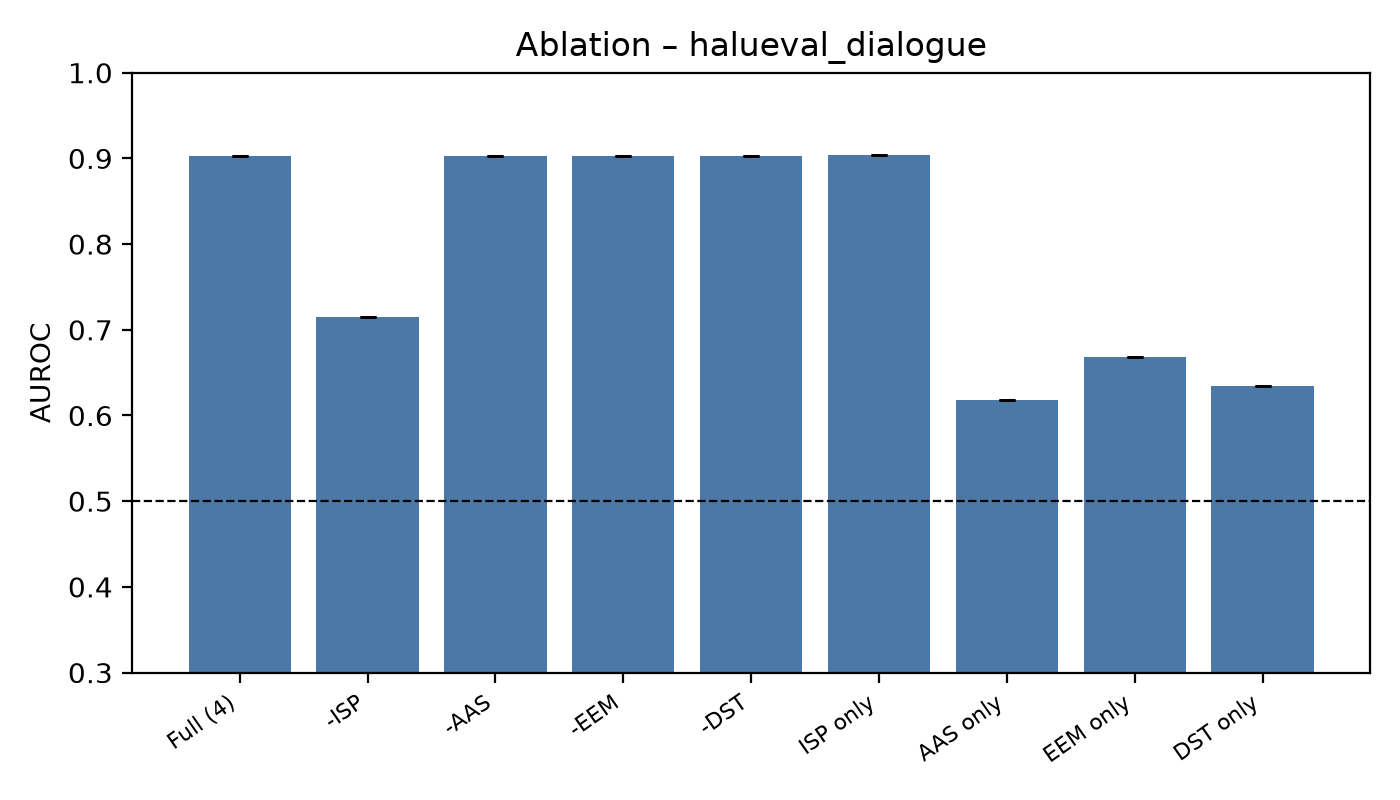

results/v2/TinyLlama__TinyLlama-1.1B-Chat-v1.0/figures/ablation_halueval_qa.png


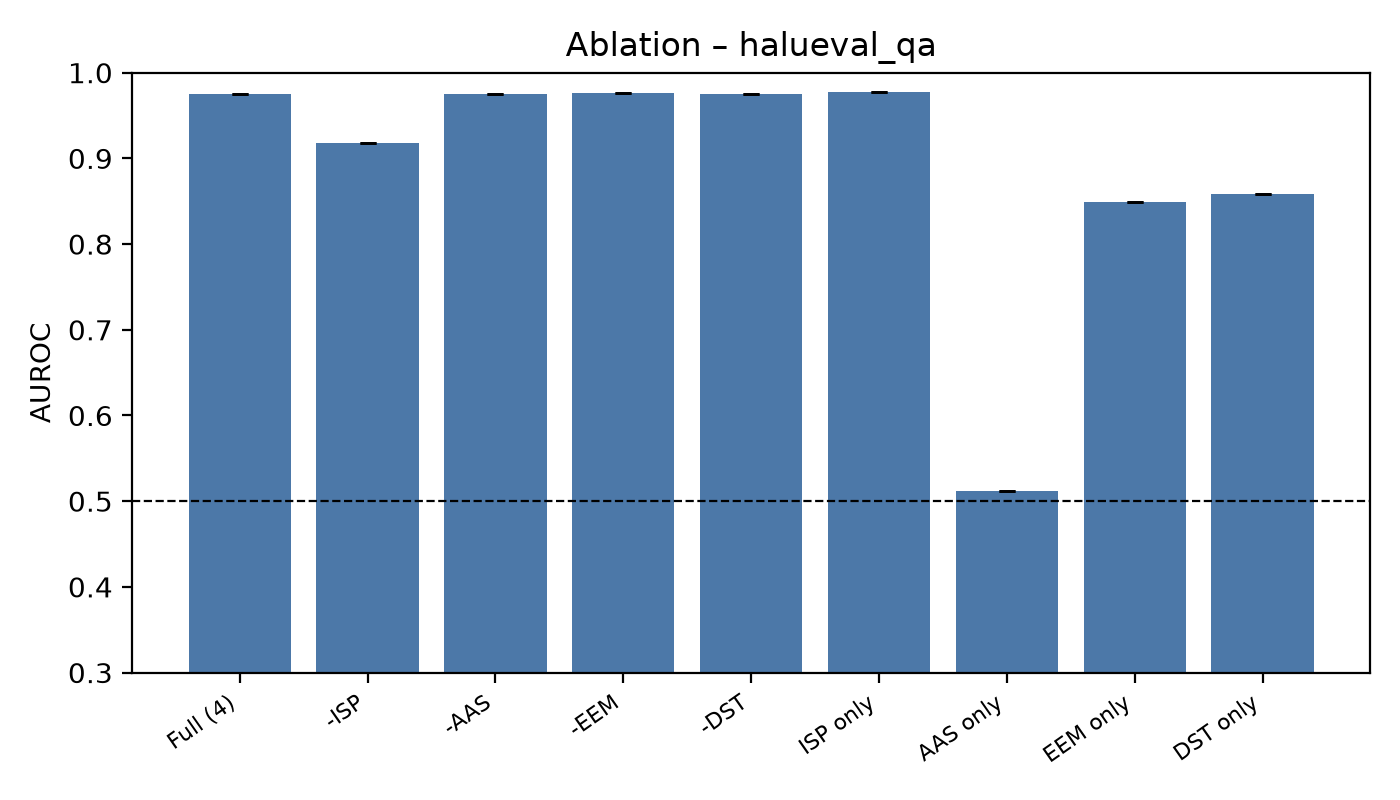

results/v2/TinyLlama__TinyLlama-1.1B-Chat-v1.0/figures/ablation_halueval_summarization.png


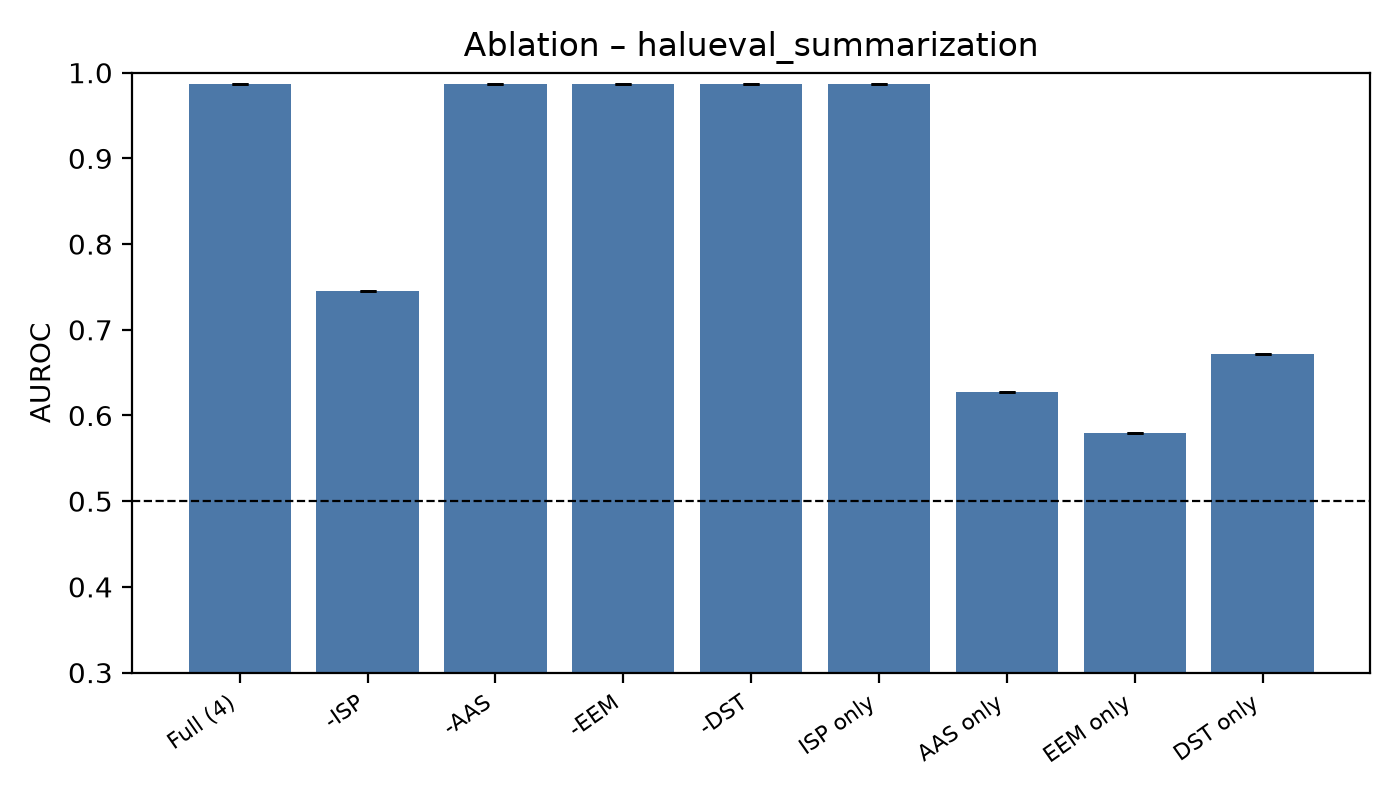

results/v2/TinyLlama__TinyLlama-1.1B-Chat-v1.0/figures/ablation_truthful_qa.png


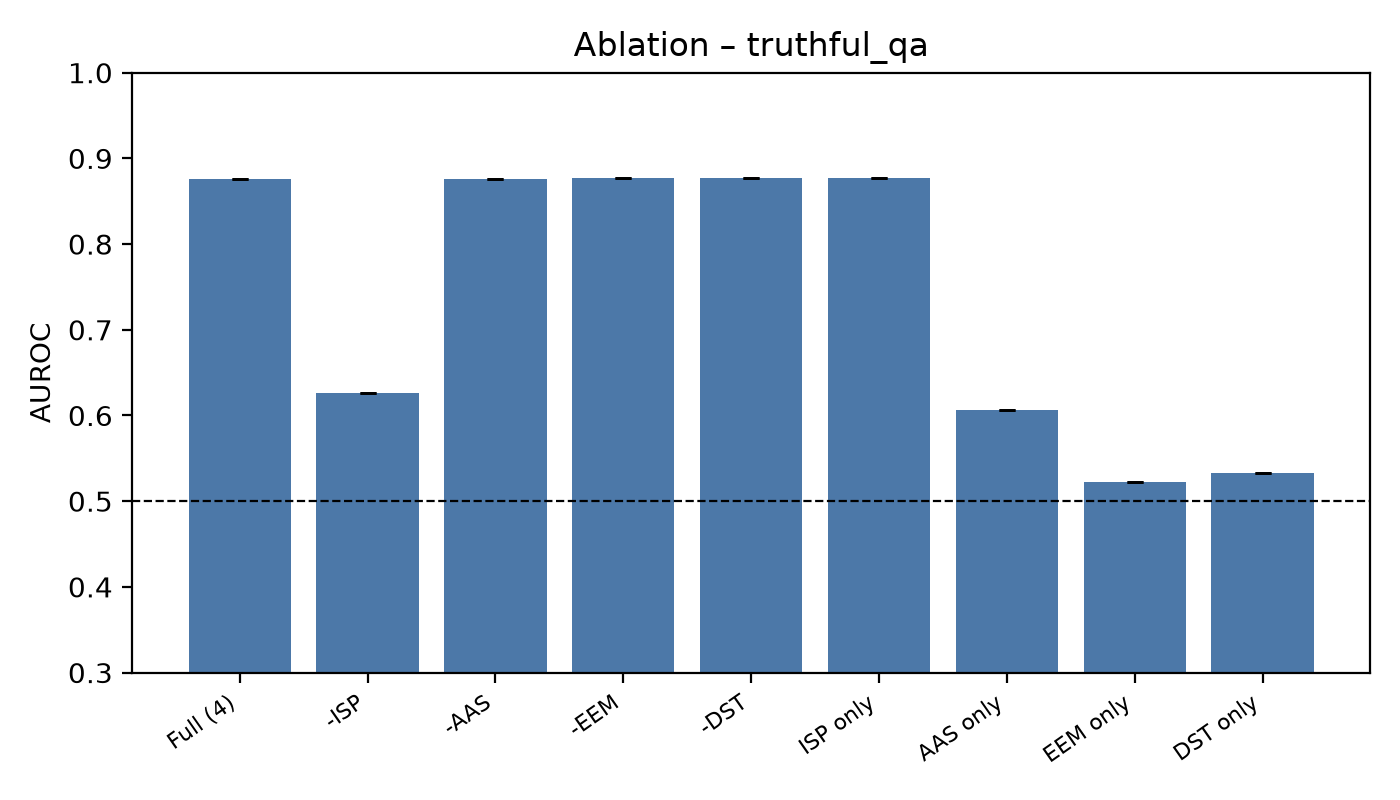

results/v2/TinyLlama__TinyLlama-1.1B-Chat-v1.0/figures/cm_halueval_dialogue.png


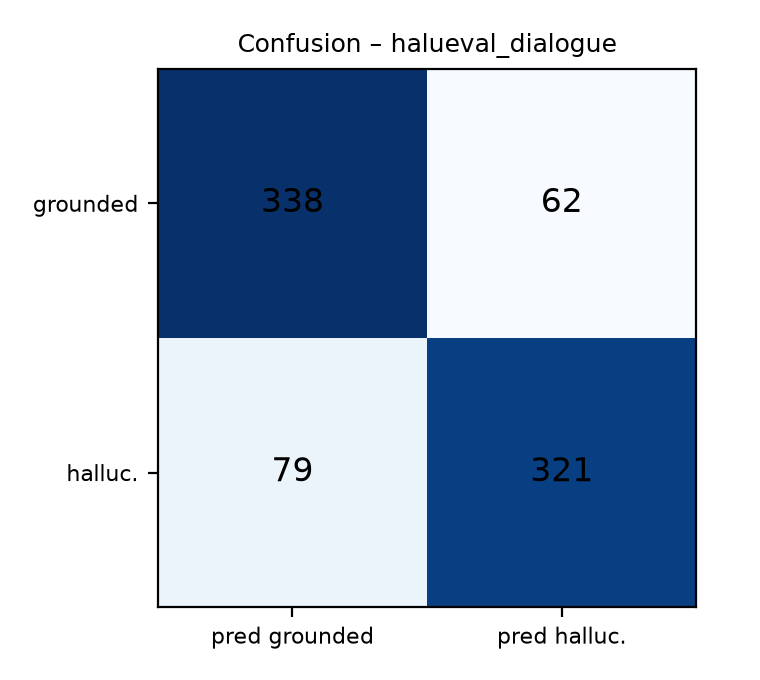

results/v2/TinyLlama__TinyLlama-1.1B-Chat-v1.0/figures/cm_halueval_qa.png


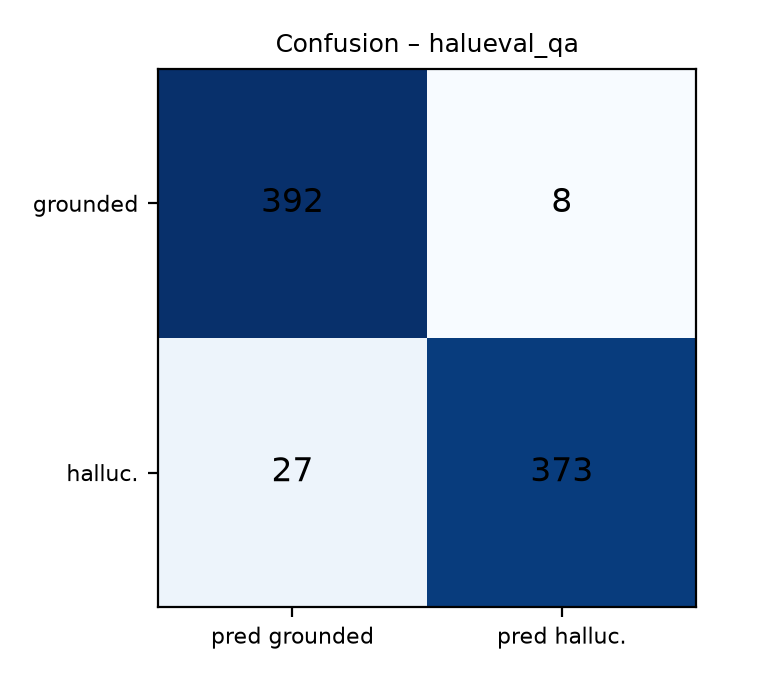

results/v2/TinyLlama__TinyLlama-1.1B-Chat-v1.0/figures/cm_halueval_summarization.png


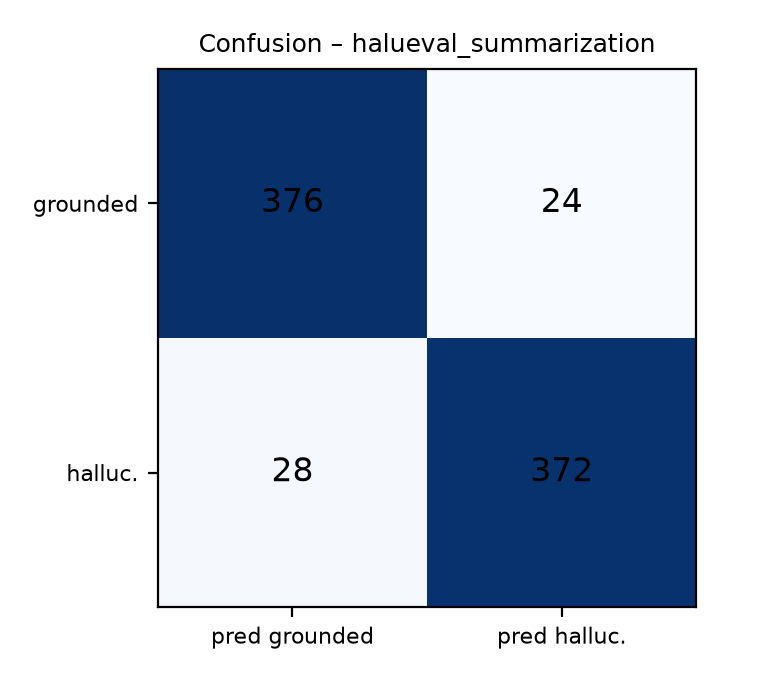

results/v2/TinyLlama__TinyLlama-1.1B-Chat-v1.0/figures/cm_truthful_qa.png


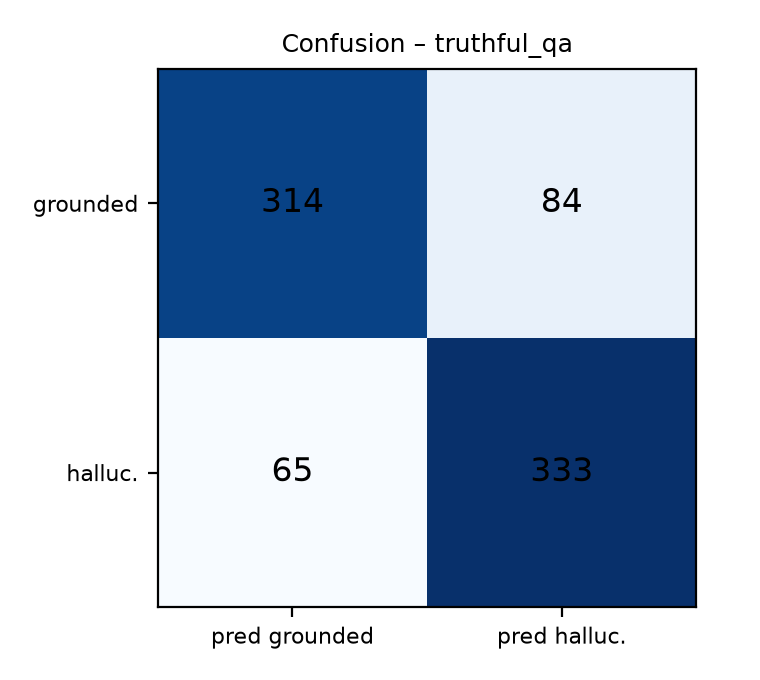

results/v2/TinyLlama__TinyLlama-1.1B-Chat-v1.0/figures/cross_dataset_matrix.png


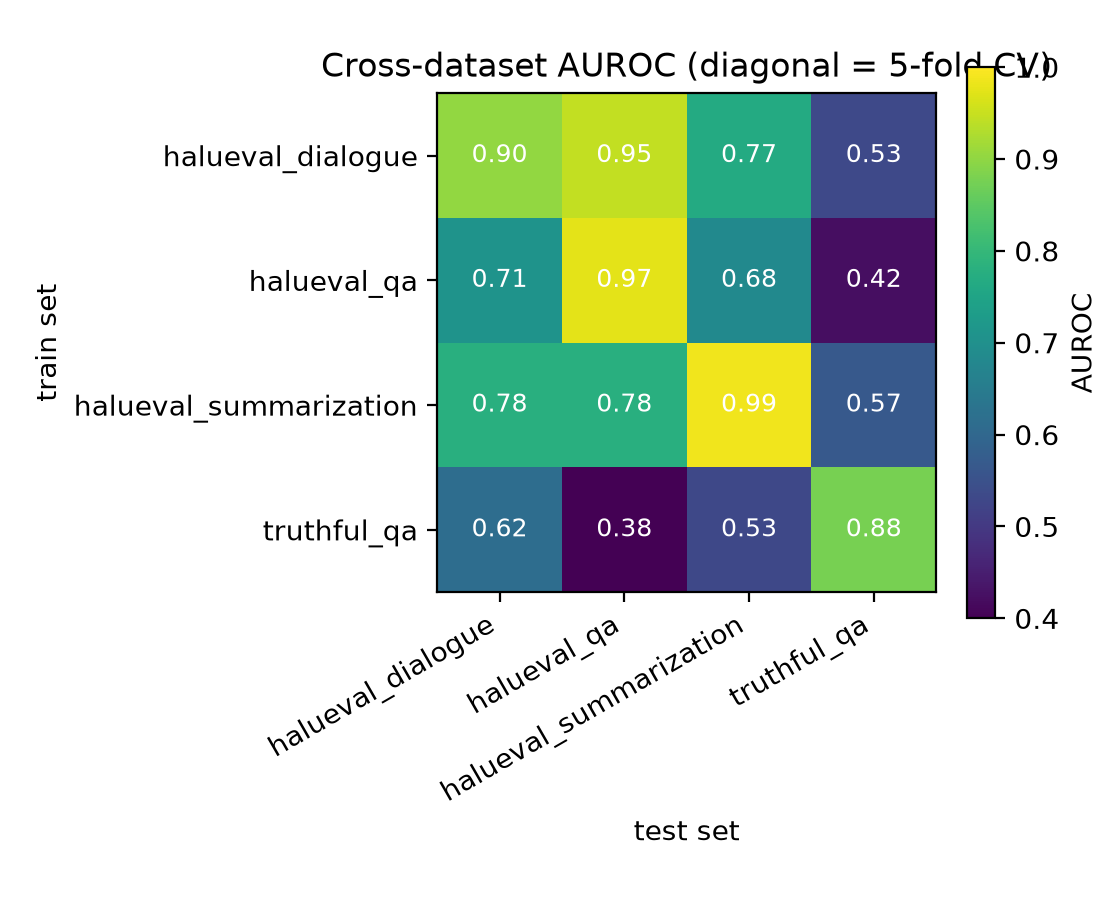

results/v2/TinyLlama__TinyLlama-1.1B-Chat-v1.0/figures/risk_halueval_dialogue.png


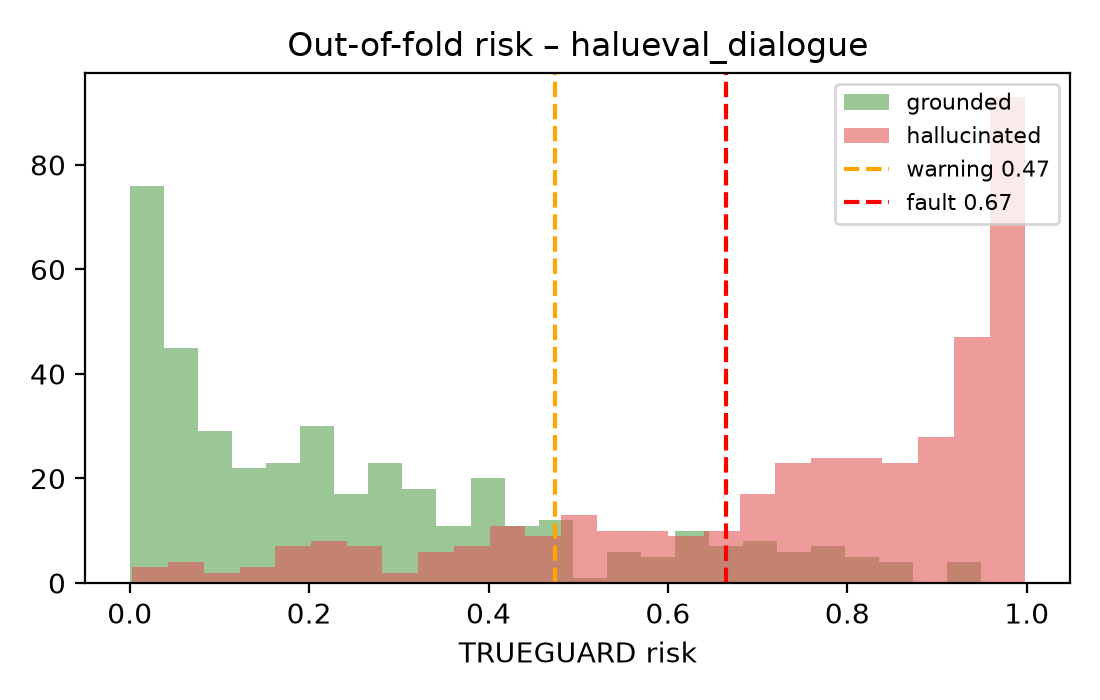

results/v2/TinyLlama__TinyLlama-1.1B-Chat-v1.0/figures/risk_halueval_qa.png


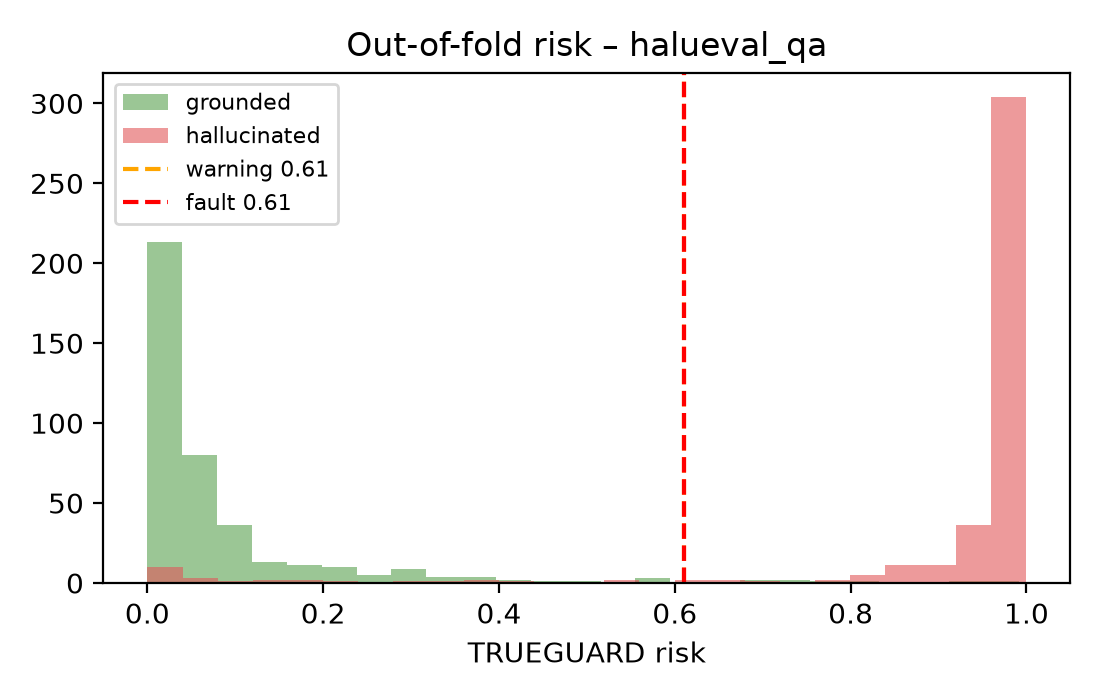

results/v2/TinyLlama__TinyLlama-1.1B-Chat-v1.0/figures/risk_halueval_summarization.png


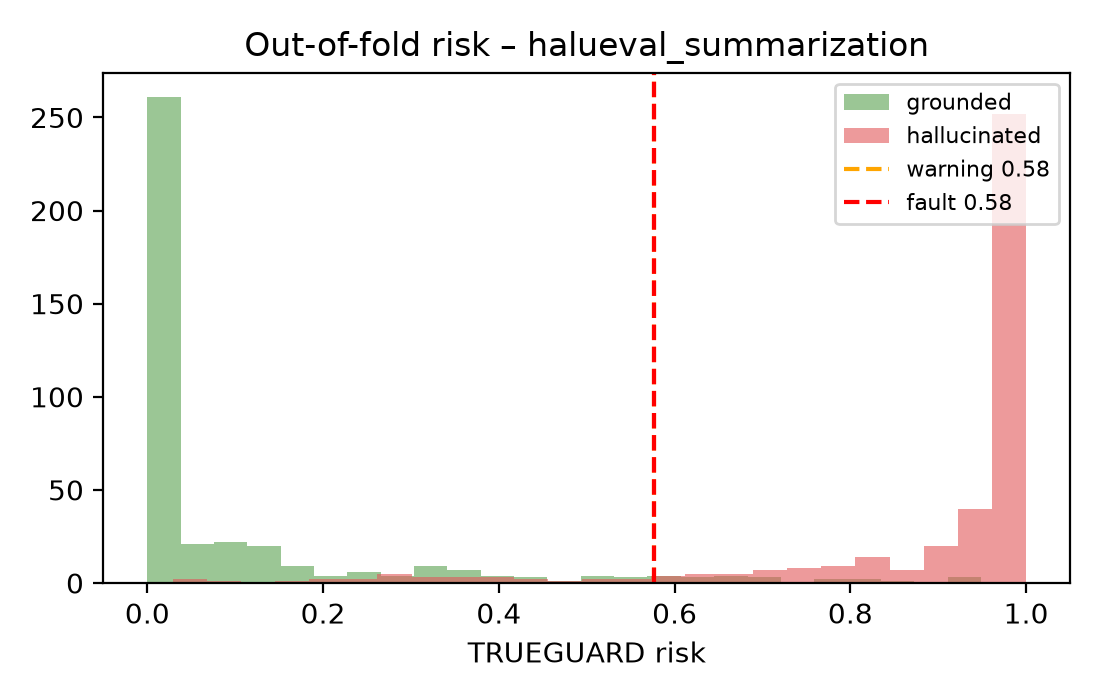

results/v2/TinyLlama__TinyLlama-1.1B-Chat-v1.0/figures/risk_truthful_qa.png


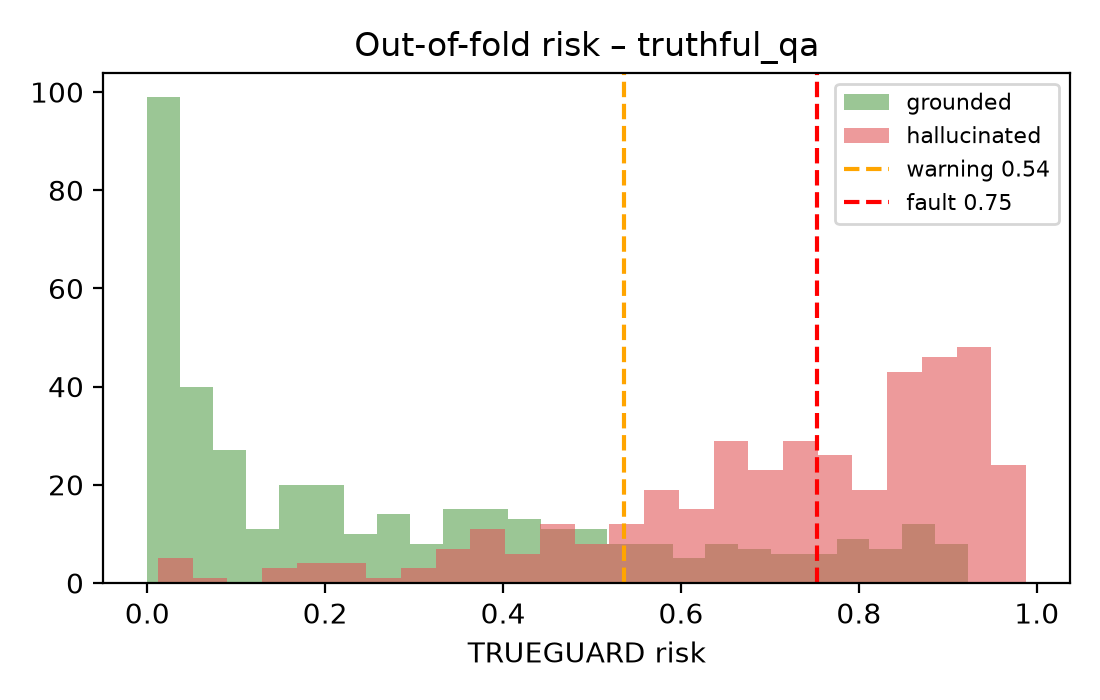

results/v2/TinyLlama__TinyLlama-1.1B-Chat-v1.0/figures/roc_halueval_dialogue.png


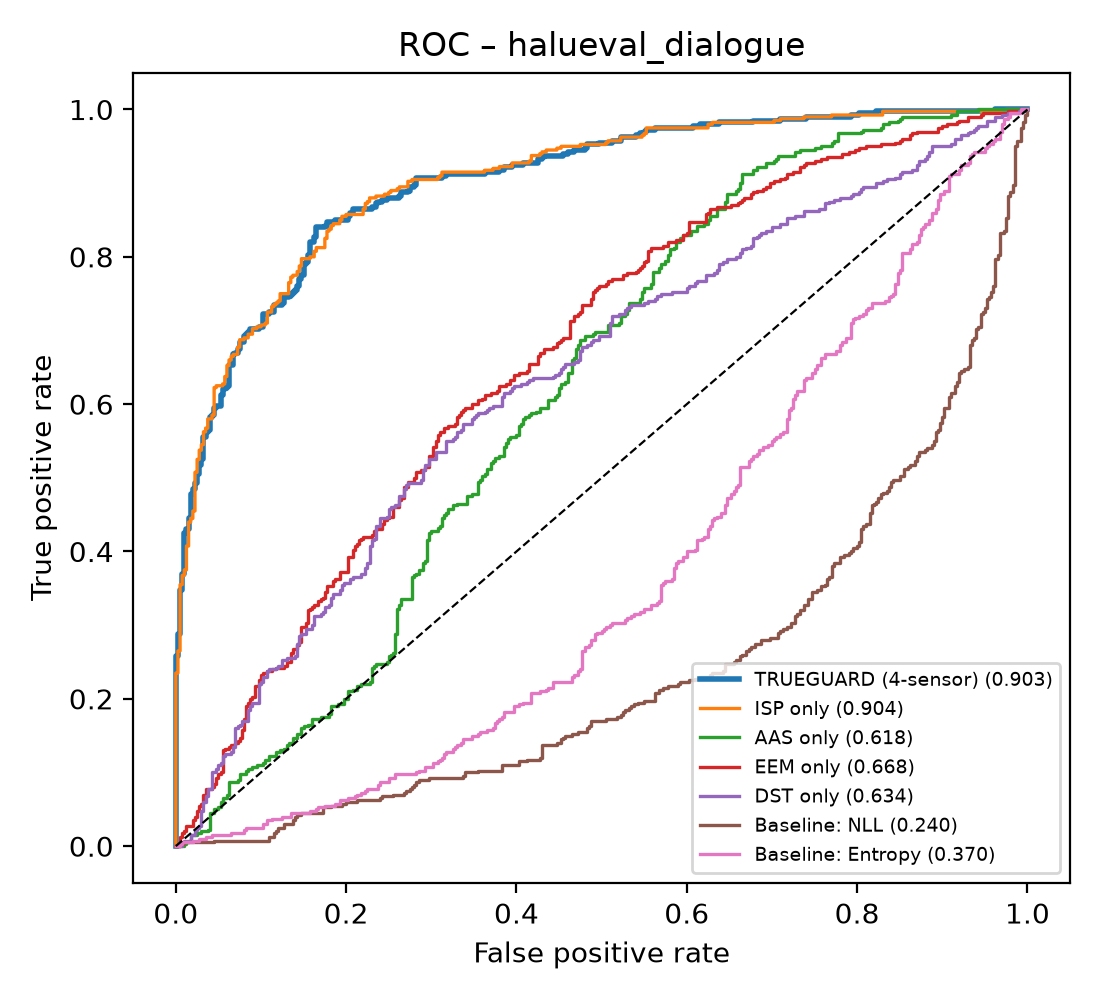

results/v2/TinyLlama__TinyLlama-1.1B-Chat-v1.0/figures/roc_halueval_qa.png


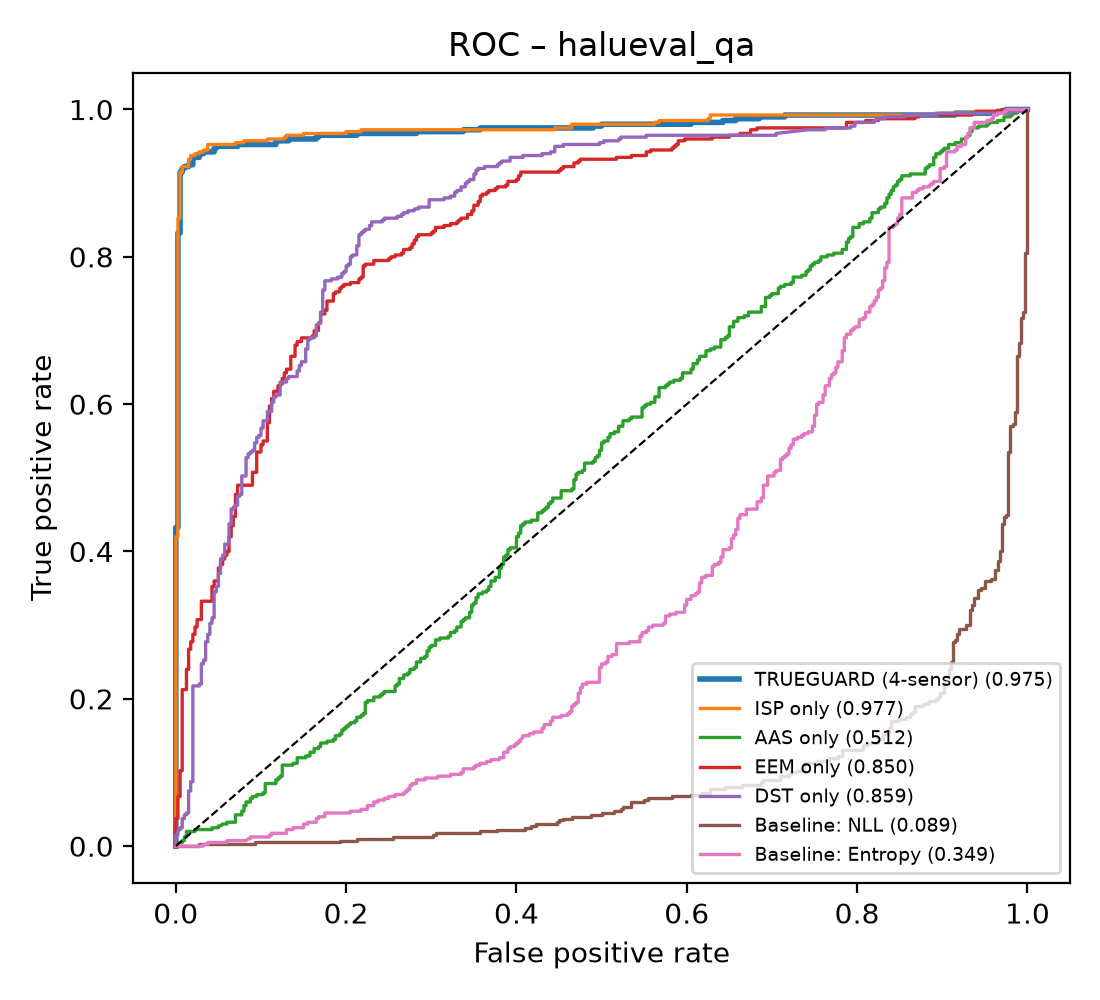

results/v2/TinyLlama__TinyLlama-1.1B-Chat-v1.0/figures/roc_halueval_summarization.png


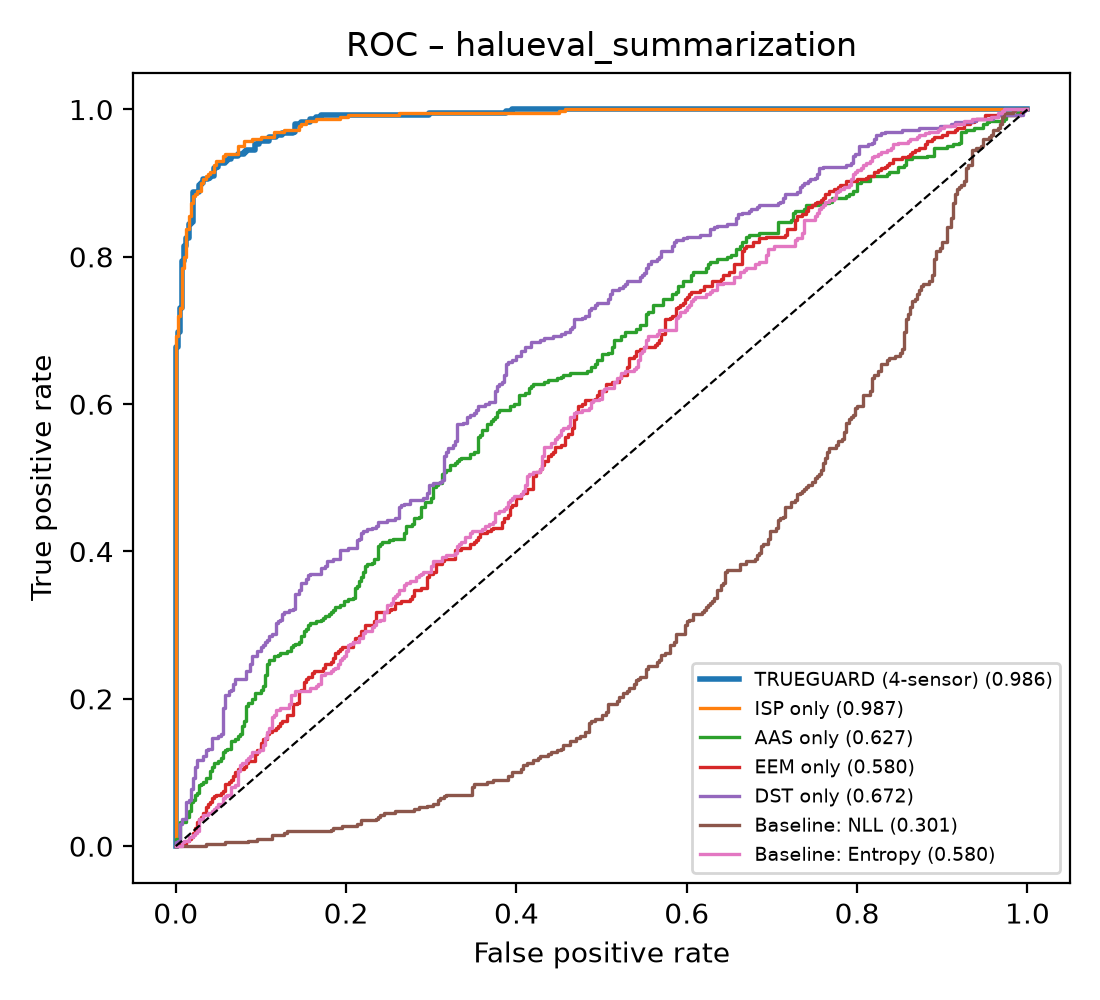

results/v2/TinyLlama__TinyLlama-1.1B-Chat-v1.0/figures/roc_truthful_qa.png


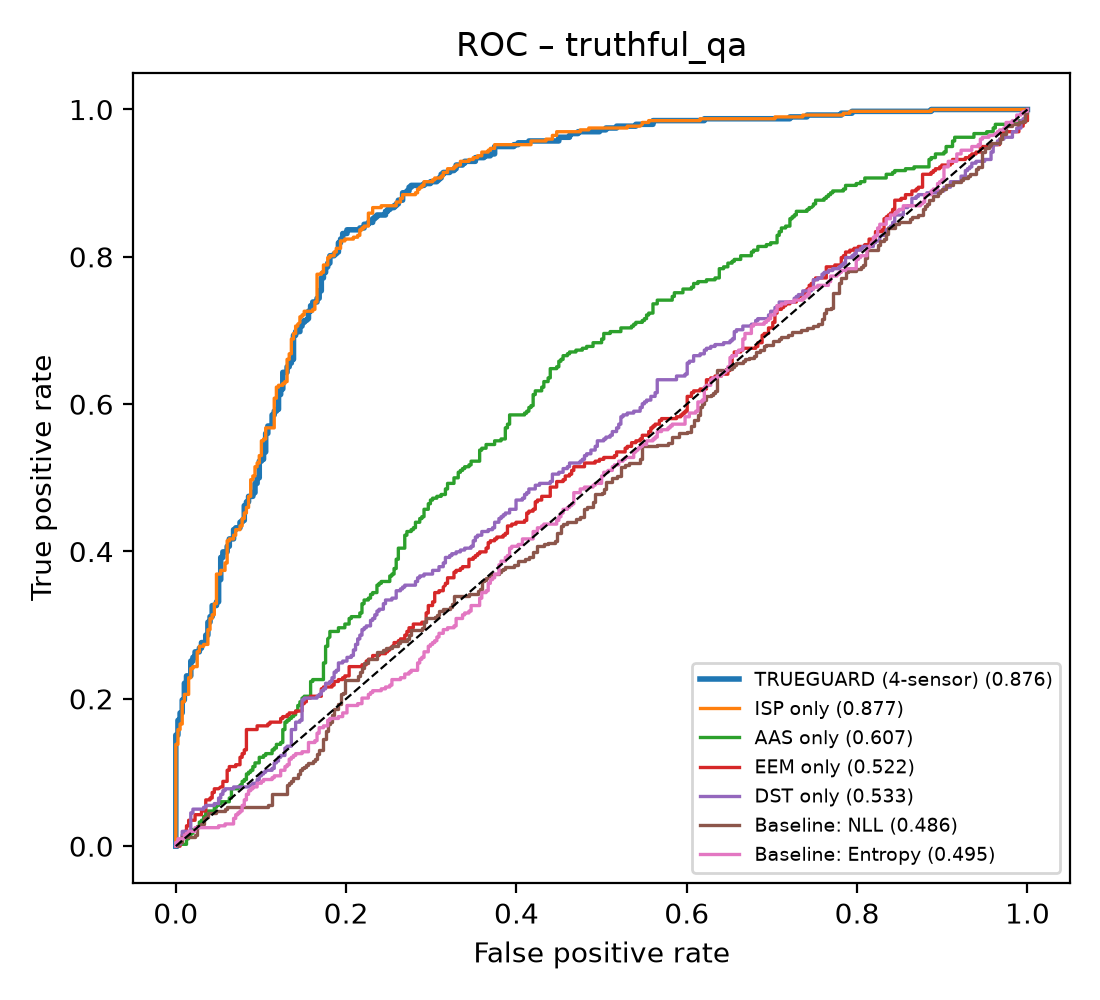

In [9]:
import glob
for p in sorted(glob.glob(f"results/v2/{TAG}/figures/*.png")):
    print(p)
    display(Image(filename=p, width=520))

## 9. Step 3 — End-to-end three-tier mitigation evaluation on TriviaQA (before vs after)
Calibrates $(\tau_{\text{warning}},\tau_{\text{fault}})$ on 150 calibration questions, then runs the closed-loop controller on 150 disjoint test questions.

In [10]:
!python -u experiments/evaluate_mitigation.py --model "$MODEL" --n_cal 150 --n_test 150 --out "results/v2/$TAG/mitigation" $FOURBIT
import json
mit = json.load(open(f"results/v2/{TAG}/mitigation/mitigation_report.json"))
print(json.dumps({k: v for k, v in mit.items() if k != "examples"}, indent=2))

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100% 201/201 [00:01<00:00, 114.26it/s]
[mitigation] scoring calibration split (n=150)...
[transformers] Both `max_new_tokens` (=24) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=24) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=24) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_token

## 10. Step 4 — Real per-token latency profiling (vanilla vs TRUEGUARD vs 5-sample baseline)

In [11]:
!python -u experiments/profile_real_latency.py --model "$MODEL" --n_prompts 25 --n_tokens 24 --out "results/v2/$TAG/real_latency.json" $FOURBIT

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100% 201/201 [00:01<00:00, 120.71it/s]
[transformers] Both `max_new_tokens` (=24) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=24) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=24) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=24) and `max_length`(=2048) seem to have been

## 11. Interactive single-prompt walkthrough (input → 4 sensors → fusion → tier decision → final answer)

In [12]:
from src.tg_pipeline import load_model, TrueGuardDetector
from src.tg_eval import calibrate_thresholds
from src.tg_controller import ThreeTierController, WikipediaRetriever
import numpy as np, json

d = np.load(f"results/cache/{TAG}/halueval_qa.npz")
det = TrueGuardDetector().fit(d["F"], d["H"], d["y"], d["groups"])
tw, tf = calibrate_thresholds(d["y"], det.train_risk_)
model, tok, dev = load_model(MODEL, load_in_4bit=bool(FOURBIT))
ctrl = ThreeTierController(model, tok, dev, det, tw, tf, retriever=WikipediaRetriever())

for q in [
    "Answer the question briefly in one short sentence.\nQuestion: What is the capital city of France?",
    "Answer the question briefly in one short sentence.\nQuestion: Which treaty ended the War of the Triple Alliance in 1870?",
]:
    print("=" * 80)
    print(q)
    print(json.dumps(ctrl.respond(q), indent=2))

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=24) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Answer the question briefly in one short sentence.
Question: What is the capital city of France?


[transformers] Both `max_new_tokens` (=24) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=24) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


{
  "initial_answer": "The capital city of France is Paris.",
  "initial_risk": 0.9931341573443507,
  "sensor_contributions": {
    "ISP": 4.80089591001202,
    "AAS": 0.06539932928758763,
    "EEM": -0.13960661009692002,
    "DST": -0.12721442839761693
  },
  "trace": [
    {
      "step": "initial_greedy",
      "answer": "The capital city of France is Paris.",
      "risk": 0.9931341573443507
    },
    {
      "step": "tier2_retrieval",
      "answer": "The capital city of France is Paris.",
      "risk": 0.9930025740370197,
      "evidence": "In the United States, capital punishment (also known as the death penalty) is a legal penalty in 27 states (of which two, Oregon and Wyoming, have no inmates sentenced to death), throughout the countr"
    }
  ],
  "tier": "TIER3_ABSTAIN",
  "final_answer": "I do not have sufficient verified evidence to answer this reliably.",
  "final_risk": 0.9931341573443507
}
Answer the question briefly in one short sentence.
Question: Which treaty ended 

[transformers] Both `max_new_tokens` (=24) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


{
  "initial_answer": "The Treaty of Frankfurt ended the War of the Triple Alliance in 1870.",
  "initial_risk": 0.9611820158892487,
  "sensor_contributions": {
    "ISP": 2.937368997877356,
    "AAS": 0.013348594976126144,
    "EEM": -0.14794528827158118,
    "DST": 0.03167506293449686
  },
  "trace": [
    {
      "step": "initial_greedy",
      "answer": "The Treaty of Frankfurt ended the War of the Triple Alliance in 1870.",
      "risk": 0.9611820158892487
    },
    {
      "step": "tier2_retrieval",
      "answer": "The Treaty of Frankfurt ended the Franco-Prussian War, also known as the Franco-German War,",
      "risk": 0.9368724099876835,
      "evidence": "The Franco-Prussian War, occasionally known as the Franco-German War, and sometimes referred to in France as the War of 1870, was a conflict between France and the North German Confederation led by Pr"
    }
  ],
  "tier": "TIER3_ABSTAIN",
  "final_answer": "I do not have sufficient verified evidence to answer this reliabl

## 12. Package and download all experimental outputs

In [13]:
!zip -q -r trueguard_v2_results.zip "results/v2/$TAG"
from google.colab import files
files.download("trueguard_v2_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>